# ITT Pulmón de Oriente — Comunas 13 y 14, Cali

**Zona:** Pulmón de Oriente (33 barrios, principalmente Comunas 13 y 14). Área aproximada 568 ha (envolvente de los eventos; polígono oficial pendiente).

**Fase 1 (datos disponibles):** Seguridad (homicidios, hurtos) y Cohesión Social (VIF, riñas, SPA). Movilidad, Entorno Urbano, Desarrollo Económico y Educación quedan **pendientes** (sin datos aún) y aparecen como vacío (NaN) hasta que se carguen. El ITT se calcula parcial con lo disponible.

**Nota de datos:** los eventos de seguridad vienen ya recortados a la zona (`_Pulmon_O`). VIF se filtró por los 33 barrios de la zona (no vino recortado espacialmente). No hay extensiones 2026 Q2-Q3: la cobertura DATIC llega hasta 2026-Q1.


## Celda 1 — Instalación de dependencias (Colab)

In [72]:
import subprocess, sys

def check_pkg(import_name, pip_name=None):
    """Importa import_name; si falta, instala pip_name (por defecto = import_name).
    Necesario para casos como PIL->pillow donde el nombre de import != nombre pip."""
    try:
        __import__(import_name)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", pip_name or import_name, "-q"])

# rasterio: lee los rasters NDVI de Entorno Urbano (Celda 3B).
# osmnx: red peatonal OSM del mapa (Celda 5). PIL(pillow): overlays NDVI del mapa.
# Colab NO trae rasterio/osmnx preinstalados, por eso van en esta lista.
for p in ["geopandas", "pyproj", "shapely", "openpyxl", "seaborn", "folium", "rasterio", "osmnx"]:
    check_pkg(p)
check_pkg("PIL", "pillow")
print("Dependencias verificadas")


Dependencias verificadas


## Celda 1B — Clonar/actualizar el repo (Colab)

**Importante:** esta celda SÍ se ejecuta (no está comentada). Si ya existe `/content/itt_repos_cali`
hace `git pull` en vez de clonar de nuevo — así se puede re-ejecutar el notebook sin reiniciar el runtime
cada vez que se actualiza el repo. Mismo patrón que `04_itt_barrio_obrero_5dim.ipynb` (Celda 3A).

In [73]:
import os
from pathlib import Path
REPO_URL  = "https://github.com/j0rg3c45/Itt_repos_cali.git"
REPO_PATH = "/content/itt_repos_cali"
# Clon superficial (--depth 1) + sparse-checkout: solo las carpetas que ESTE notebook usa.
# Pulmón de Oriente usa data/itt_pulmon_oriente (seguridad/cohesion/movilidad) + las fuentes
# generales de Cámara de Comercio, vivienda y educación para las dimensiones DE/EU/Educación.
SPARSE_DIRS = [
    "data/itt_pulmon_oriente",       # seguridad, cohesion, movilidad + poligono
    "data/Camara_de_Comercio",       # Desarrollo Económico (registro mercantil)
    "data/sec_vivienda",             # Vivienda (déficit habitacional SISBÉN) -> Entorno Urbano
    "data/Educacion_2026",           # SIMAT/SIMPADE (Educación)
    "docs", "tools", "agent", "outputs",
]
import shutil, subprocess
shutil.rmtree(REPO_PATH, ignore_errors=True)
subprocess.run(["git", "clone", "--depth", "1", "--filter=blob:none", "--sparse",
                REPO_URL, REPO_PATH], check=True)
subprocess.run(["git", "-C", REPO_PATH, "sparse-checkout", "set", *SPARSE_DIRS], check=True)
DATA_DIR_CHECK = Path("/content/itt_repos_cali/data/itt_pulmon_oriente")
print()
print("Carpetas disponibles en data/itt_pulmon_oriente:")
if DATA_DIR_CHECK.exists():
    for p in sorted(DATA_DIR_CHECK.iterdir()):
        print(f"  {'OK' if p.is_dir() or p.suffix == '.geojson' else '  '}  {p.name}")
else:
    print("  NO EXISTE — revisar que el clone de arriba haya terminado sin error.")
# Verificacion del poligono (origen del DataSourceError si falta).
_poly = DATA_DIR_CHECK / "geojson_pulmon_oriente.geojson"
print()
print("OK  poligono presente." if _poly.exists() else "FALTA  geojson_pulmon_oriente.geojson no esta en la copia local.")



Carpetas disponibles en data/itt_pulmon_oriente:
  OK  1_Dimension_Seguridad
  OK  2_Dimension_Cohesion_Social
  OK  3_Dimension_Movilidad
  OK  4_Dimension_Desarrollo_Economico
  OK  5_Entorno_Urbano
  OK  6_Dimension_Educacion
      Pulmon_De_Oriente_2026.zip
      barrios_pulmon_oriente.json
  OK  geojson_pulmon_oriente.geojson

OK  poligono presente.


## Celda 2 — Importaciones y configuración visual

In [74]:
import json, os, re, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import folium
from shapely.geometry import Point
warnings.filterwarnings("ignore")

# Paleta Okabe-Ito (accesible para daltonismo) — misma paleta que el resto del proyecto
OKI_AZUL     = "#0072B2"
OKI_NARANJA  = "#E69F00"
OKI_VERDE    = "#009E73"
OKI_AMARILLO = "#F0E442"
OKI_AZUL_C   = "#56B4E9"
OKI_BERMELL  = "#D55E00"
OKI_MORADO   = "#CC79A7"
OKI_GRIS     = "#333333"
BG = "#F4F6F9"

NIVEL_COLORS = {
    "Activacion":     OKI_BERMELL,
    "Consolidacion":  OKI_NARANJA,
    "Transformacion": OKI_VERDE,
    "Escala":         OKI_AZUL,
}

plt.rcParams.update({
    "figure.facecolor": BG, "axes.facecolor": "white",
    "font.family": "DejaVu Sans",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3,
})
print("Configuracion visual lista - Paleta Okabe-Ito activa")


Configuracion visual lista - Paleta Okabe-Ito activa


## Celda 3 — Parámetros, rutas, pesos y umbrales ref_min/ref_max

In [75]:
REPO = Path("/content/itt_repos_cali")
D    = REPO / "data" / "itt_pulmon_oriente"
# Para ejecucion local descomentar:
# REPO = Path(".")
# D    = REPO / "data" / "itt_pulmon_oriente"
# Rutas a los archivos de Pulmón de Oriente. Cobertura DATIC: 2023 -> 2026-Q1 (sin
# extensiones Q2-Q3). Los eventos de seguridad vienen ya recortados a la zona; VIF se
# filtró por los barrios de la zona. Las demás dimensiones aún NO tienen datos (FALTA).
DIM1 = D / "1_Dimension_Seguridad"
DIM2 = D / "2_Dimension_Cohesion_Social"
DIM3 = D / "3_Dimension_Movilidad"
PATHS = {
    "poligono":     str(D / "geojson_pulmon_oriente.geojson"),       # aprox. (hull de eventos)
    "poligono_shp": str(D / "geojson_pulmon_oriente.geojson"),
    "homicidios":  [str(DIM1 / "DATIC_homicidios_2023_2026T1.geojson"),
                    str(DIM1 / "DATIC_homicidios_04012026_26092026.geojson")],
    "hurtos":      [str(DIM1 / "DATIC_hurtos_2023_2026T1.geojson"),
                    str(DIM1 / "DATIC_hurtos_04012026_09302026.geojson")],
    "comparendos": [str(DIM1 / "DATIC_comparendos_2023_2026T1.geojson"),
                    str(DIM1 / "DATIC_comparendos_04012026_09302026.geojson")],
    "vif":         [str(DIM2 / "DATIC_violencia_intrafamiliar_2023_2026T1.geojson"),
                    str(DIM2 / "DATIC_violencia_intrafamiliar_04012026_09302026.geojson")],
    # ── Fuentes AÚN NO disponibles para esta zona (quedan como FALTA / NaN) ──
    "siniestros":  [str(DIM3 / "BD_SINIESTROS_2023_2026_COMUNA_BARRIO.geojson"),
                    str(DIM3 / "BD_SINIESTROS_ABRIL_JUNIO_2026_COMUNA_BARRIO.geojson")],
    "vbg":                str(DIM2 / "VBG.geojson"),                 # pendiente
    "registro_mercantil": str(D / "4_Dimension_Desarrollo_Economico" / "registro_mercantil.geojson"),
    "de_consolidado":     str(D / "4_Dimension_Desarrollo_Economico" / "registro_mercantil_PO_consolidado.json"),
    "educ_consolidado":   str(D / "6_Dimension_Educacion" / "educacion_PO_consolidado.json"),
    # Vivienda (déficit habitacional 2024, corte único) -> componente de Entorno Urbano
    "deficit_habitacional_shp": str(REPO / "data" / "sec_vivienda" / "DEF_HAB_SISBEN.shp"),
    "censo_arboreo":      str(D / "5_Entorno_Urbano" / "CENSO_ARBOREO_poligono_Oriente.geojson"),
}
PATHS_NDVI = {ano: str(D / "5_Entorno_Urbano" / "ndvi" / f"pulmon_de_oriente_ndvi_{ano}.tif")
              for ano in [2023, 2024, 2025, 2026]}
ANIOS = [2023, 2024, 2025, 2026]
ANO_CORTE = 2026
ANIOS_PARCIALES = [2026]   # DATIC llega hasta 2026-Q1: 2026 es parcial, se muestra como GUÍA.
ZONA_NOMBRE = "Pulmón de Oriente"
COMUNA_PROXY = "13-14"   # 33 barrios, principalmente Comunas 13 y 14
# ── Pesos ITT: 5 dimensiones (suma = 1.00) — idénticos a Barrio Obrero (metodología común) ──
PESOS = {"Seguridad": 0.27, "Movilidad": 0.22, "DesSocial": 0.19, "EntornoU": 0.17, "DesEco": 0.15}
# ── Umbrales ref_min/ref_max — calibrados al rango real observado 2023-2025 de Pulmón
# de Oriente (zona grande; conteos altos). Obs.: homicidios 85-117 | hurtos 1146-1452 |
# vif 923-1126 | riñas 3365-4310 | spa 723-1223. Regla: ref_min bajo el mínimo, ref_max
# con margen sobre el máximo (sección 6.3 de la guía). Pendiente validación experto local.
REFS = {
    "homicidios":      (0,    140,  True,  "Homicidios anuales en la zona"),      # obs. 85-117
    "hurtos":          (900,  2400, True,  "Hurtos anuales en la zona"),           # obs. 1144-1447 (2026 anualizado 2125)
    "siniestralidad":  (120,  280,  True,  "Siniestros viales anuales"),           # obs. 222-236
    "lesionados":      (120,  260,  True,  "Accidentes con lesionados anuales"),    # obs. 194-222
    "mortales":        (0,    25,   True,  "Accidentes mortales anuales"),          # obs. 10-19
    "vif":             (300,  1000, True,  "Violencia intrafamiliar anual"),       # obs. 482-587 (2026 anualizado 901)
    "rinas":           (100,  950,  True,  "Riñas / conflictividad anual"),         # obs. 224-599 (2026 anualizado 825)
    "spa":             (400,  1750, True,  "Sustancias psicoactivas (comparendos) anuales"),  # obs. 721-1220 (2026 anualizado 1575)
    "ndvi":            (0.05, 0.20, False, "NDVI medio anual (pendiente)"),
    "arbolado":        (0,    400,  False, "Arboles vivos censados (pendiente)"),
}
FUENTE_ENTORNO_U = "NDVI satelital anual + censo arbóreo (árboles vivos) + habitabilidad (SISBÉN) propios de la zona"
print(f"Zona: {ZONA_NOMBRE}  |  Periodo: {ANIOS[0]}-{ANIOS[-1]}  |  Comunas: {COMUNA_PROXY}")
for nombre, path in PATHS.items():
    _rutas = path if isinstance(path, (list, tuple)) else [path]
    _exist = [os.path.exists(r) for r in _rutas]
    mark = "OK   " if all(_exist) else ("PARCIAL" if any(_exist) else "FALTA")
    _nombres = ", ".join(os.path.basename(r) for r in _rutas)
    print(f"  {mark:7s}  {nombre}: {_nombres}")
print()
print("Pesos ITT (5 dimensiones):", " | ".join(f"{k}={v:.0%}" for k, v in PESOS.items()))
print("Fase 1: Seguridad + Cohesión con datos; Movilidad/EntornoU/DesEco/Educación pendientes (NaN).")


Zona: Pulmón de Oriente  |  Periodo: 2023-2026  |  Comunas: 13-14
  OK       poligono: geojson_pulmon_oriente.geojson
  OK       poligono_shp: geojson_pulmon_oriente.geojson
  OK       homicidios: DATIC_homicidios_2023_2026T1.geojson, DATIC_homicidios_04012026_26092026.geojson
  OK       hurtos: DATIC_hurtos_2023_2026T1.geojson, DATIC_hurtos_04012026_09302026.geojson
  OK       comparendos: DATIC_comparendos_2023_2026T1.geojson, DATIC_comparendos_04012026_09302026.geojson
  OK       vif: DATIC_violencia_intrafamiliar_2023_2026T1.geojson, DATIC_violencia_intrafamiliar_04012026_09302026.geojson
  OK       siniestros: BD_SINIESTROS_2023_2026_COMUNA_BARRIO.geojson, BD_SINIESTROS_ABRIL_JUNIO_2026_COMUNA_BARRIO.geojson
  FALTA    vbg: VBG.geojson
  FALTA    registro_mercantil: registro_mercantil.geojson
  OK       de_consolidado: registro_mercantil_PO_consolidado.json
  OK       educ_consolidado: educacion_PO_consolidado.json
  OK       deficit_habitacional_shp: DEF_HAB_SISBEN.shp
  OK      

## Celda 3B — Entorno Urbano real: NDVI anual + censo arbóreo

**Actualizado 2026-10-07.** Antes esta celda calculaba un *proxy* de déficit habitacional de la Comuna 3
porque la zona no tenía datos ambientales propios. Ya los tiene (`5_Dimension_Entorno_Urbano/`), así que se
reemplaza por el cálculo real, con el **mismo método que `06_itt_avenida_ciudad_de_cali_5dim.ipynb`**:

- **NDVI**: media del ráster de cada año (`np.nanmean`), descartando `nodata`. Aporta la señal temporal
  (la vegetación sí cambia año a año).
- **Arbolado**: conteo de árboles vivos (`estado_arb ∈ {Vivo, Nuevo}`) dentro del polígono, verificado por
  `sjoin` igual que el resto de fuentes. Es un corte único del censo, así que es constante en los 4 años.
- `score_entorno_u = mean(score_ndvi, score_arbolado)` con `inverso=False` (más verde / más árboles = mejor).

Los umbrales `ndvi`/`arbolado` de la Celda 3 se **recalibran aquí** sobre el rango real observado de la zona
(regla sección 6.3 de `agent/knowledge_base/Guia_ITT_Metodologia_Notebook.md`): `ref_min` por debajo del mínimo
observado, `ref_max` con margen sobre el máximo. Pendiente de validación por experto local del territorio.

In [76]:
# Fallback por si la Celda 1 no se corrio: rasterio no viene preinstalado en Colab.
try:
    import rasterio
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "rasterio", "-q"])
    import rasterio

def _ndvi_medio(path):
    """Media NDVI del raster, descartando nodata y centinelas -9999."""
    with rasterio.open(path) as src:
        arr = src.read(1).astype("float64")
        if src.nodata is not None:
            arr[arr == src.nodata] = np.nan
        arr[arr <= -9999] = np.nan
        return float(np.nanmean(arr))

# ── NDVI medio por año (señal temporal de Entorno Urbano) ────────────────────
ndvi_por_anio = {}
for ano in ANIOS:
    p = PATHS_NDVI.get(ano)
    ndvi_por_anio[ano] = _ndvi_medio(p) if (p and os.path.exists(p)) else np.nan

# ── Censo arbóreo: árboles VIVOS dentro del polígono real (sjoin, no campo 'comuna') ─
# gdf_zona_wgs se carga normalmente en la Celda 4; aqui lo cargamos si aun no existe
# para que esta celda sea autosuficiente y funcione en cualquier orden de ejecucion.
if "gdf_zona_wgs" not in dir():
    gdf_zona_wgs = gpd.read_file(PATHS["poligono"]).to_crs("EPSG:4326")

# Censo arbóreo: tolerante a que la fuente aún no exista en la zona.
if os.path.exists(PATHS["censo_arboreo"]):
    gdf_arb_all = gpd.read_file(PATHS["censo_arboreo"]).to_crs("EPSG:4326")
    _join_arb = gpd.sjoin(gdf_arb_all, gdf_zona_wgs[["geometry"]], how="left", predicate="within")
    _dentro_arb = _join_arb["index_right"].notna()
    _vivos = gdf_arb_all["estado_arb"].astype(str).str.strip().isin(["Vivo", "Nuevo"])
    gdf_arb = gdf_arb_all[_dentro_arb.values & _vivos.values].copy()
    ARBOLADO_VIVO = int(len(gdf_arb))
    ARBOLADO_TOTAL_CENSADO = int(_dentro_arb.sum())
else:
    print("  [FALTA] censo arbóreo -> arbolado = 0 (Entorno Urbano usará solo NDVI si existe)")
    gdf_arb = gpd.GeoDataFrame(geometry=[], crs="EPSG:4326")
    ARBOLADO_VIVO = 0
    ARBOLADO_TOTAL_CENSADO = 0

# ── Recalibrar umbrales REFS['ndvi'] y REFS['arbolado'] sobre el rango real de la zona ─
_ndvi_vals = [v for v in ndvi_por_anio.values() if pd.notna(v)]
if _ndvi_vals:
    _nmin, _nmax = min(_ndvi_vals), max(_ndvi_vals)
    _margen = max((_nmax - _nmin) * 0.5, 0.02)
    REFS["ndvi"] = (round(max(0.0, _nmin - _margen), 3), round(_nmax + _margen, 3), False,
                    "NDVI medio anual (vegetacion) del raster de la zona")
REFS["arbolado"] = (0, max(1, round(ARBOLADO_VIVO * 1.5)), False,
                    "Arboles vivos censados dentro del poligono")

# ── Tabla anual de Entorno Urbano (lo que consume la Celda 7) ────────────────
df_entorno = pd.DataFrame({
    "año":      ANIOS,
    "ndvi":     [ndvi_por_anio[a] for a in ANIOS],
    "arbolado": [ARBOLADO_VIVO] * len(ANIOS),   # corte único del censo (constante en el tiempo)
})

print(f"Entorno Urbano REAL activado para {ZONA_NOMBRE} (NDVI + censo arbóreo)")
print(f"Censo arbóreo: {ARBOLADO_TOTAL_CENSADO} árboles dentro del polígono | {ARBOLADO_VIVO} vivos/nuevos (usados)")
print(f"Umbral NDVI recalibrado: {REFS['ndvi'][0]} - {REFS['ndvi'][1]}  |  Umbral arbolado: 0 - {REFS['arbolado'][1]}")
print()
print("NDVI medio por año:")
for a in ANIOS:
    v = ndvi_por_anio[a]
    print(f"  {a}: {'N/D' if pd.isna(v) else f'{v:.4f}'}")


Entorno Urbano REAL activado para Pulmón de Oriente (NDVI + censo arbóreo)
Censo arbóreo: 20459 árboles dentro del polígono | 20196 vivos/nuevos (usados)
Umbral NDVI recalibrado: 0.161 - 0.224  |  Umbral arbolado: 0 - 30294

NDVI medio por año:
  2023: 0.1808
  2024: 0.1886
  2025: 0.2043
  2026: 0.2028


## Celda 4 — Carga de datos crudos (GeoJSON + polígono)

In [77]:
def load_gj(path):
    """Carga un GeoJSON y devuelve una FeatureCollection.
    - Acepta una ruta (str) o una LISTA de rutas: en ese caso CONCATENA los features
      de todas (p.ej. histórico 2023-2026T1 + extensión Q2-Q3 2026 en una sola serie).
    - Si un archivo no existe (fuente aún no agregada), lo omite sin romper — así el
      notebook corre por fases mientras se cargan las dimensiones."""
    rutas = path if isinstance(path, (list, tuple)) else [path]
    feats = []
    for r in rutas:
        if not os.path.exists(r):
            print(f"  [FALTA] {os.path.basename(r)} -> 0 registros de esta parte")
            continue
        with open(r, encoding="utf-8") as f:
            feats.extend(json.load(f).get("features", []))
    return {"type": "FeatureCollection", "features": feats}

# Poligono real de la zona — se usa para la verificacion espacial de la Celda 4B,
# no solo para el mapa.
gdf_zona = gpd.read_file(PATHS["poligono"])
gdf_zona_wgs = gdf_zona.to_crs("EPSG:4326")
AREA_ZONA_M2 = round(gdf_zona.to_crs("EPSG:3115").geometry.area.sum(), 1)
AREA_ZONA_HA = round(AREA_ZONA_M2 / 10000, 2)
AREA_ZONA_KM2 = round(AREA_ZONA_M2 / 1e6, 4)
print(f"Area real del poligono (EPSG:3115): {AREA_ZONA_HA} ha  |  {AREA_ZONA_M2:,.1f} m2  |  {AREA_ZONA_KM2} km2")

raw_hom  = load_gj(PATHS["homicidios"])
raw_hur  = load_gj(PATHS["hurtos"])
raw_comp = load_gj(PATHS["comparendos"])
raw_vif  = load_gj(PATHS["vif"])
raw_vbg  = load_gj(PATHS["vbg"])
raw_sin  = load_gj(PATHS["siniestros"])
raw_de   = load_gj(PATHS["registro_mercantil"])

for n, r in [("Homicidios",raw_hom),("Hurtos",raw_hur),("Comparendos",raw_comp),
             ("VIF",raw_vif),("VBG",raw_vbg),("Siniestros",raw_sin),
             ("Registro Mercantil",raw_de)]:
    print(f"  {n:20s}: {len(r['features']):>5} registros")


Area real del poligono (EPSG:3115): 568.43 ha  |  5,684,299.4 m2  |  5.6843 km2
  [FALTA] VBG.geojson -> 0 registros de esta parte
  [FALTA] registro_mercantil.geojson -> 0 registros de esta parte
  Homicidios          :   355 registros
  Hurtos              :  5605 registros
  Comparendos         : 39214 registros
  VIF                 :  4252 registros
  VBG                 :     0 registros
  Siniestros          :   818 registros
  Registro Mercantil  :     0 registros


## Celda 4B — Verificación espacial real (mejora sobre la metodología de Obrero)

A diferencia de Barrio Obrero (donde `nom_barrio == "Barrio Obrero"` bastaba porque el único ruido eran
barrios vecinos inmediatos), en Pulmón de Oriente los campos `nom_comuna`/`BARRIO` de las fuentes DATIC y
Cámara de Comercio son poco confiables (ej. comparendos trae `nom_comuna` como `"C-22 LA MARIA"` para
puntos que están físicamente en El Calvario; Registro Mercantil trae negocios etiquetados en 14 comunas
distintas). **Esta celda no confía en esos campos** — hace `point-in-polygon` real contra la geometría
del polígono con `geopandas.sjoin`, y usa ese resultado como único filtro de verdad. Si el % dentro no es
cercano a 100%, es señal de que el archivo fuente trae puntos de fuera de la zona y hay que filtrar antes
de agregar.

In [78]:
def verificar_espacial(raw, nombre):
    # Fuente aún no agregada: máscara vacía, sin romper.
    if not raw["features"]:
        print(f"  {nombre:20s}:     0/    0 dentro del poligono  (fuente ausente)")
        return pd.Series([], dtype=bool)
    gdf = gpd.GeoDataFrame.from_features(raw["features"], crs="EPSG:4326")
    join = gpd.sjoin(gdf, gdf_zona_wgs[["geometry"]], how="left", predicate="within")
    dentro = join["index_right"].notna()
    pct = dentro.mean() * 100
    print(f"  {nombre:20s}: {dentro.sum():>5}/{len(gdf):>5} dentro del poligono  ({pct:5.1f}%)")
    return dentro

print(f"Verificacion espacial contra el poligono real ({AREA_ZONA_HA} ha):")
mask_hom  = verificar_espacial(raw_hom,  "Homicidios")
mask_hur  = verificar_espacial(raw_hur,  "Hurtos")
mask_comp = verificar_espacial(raw_comp, "Comparendos")
mask_vif  = verificar_espacial(raw_vif,  "VIF")
mask_sin  = verificar_espacial(raw_sin,  "Siniestros")
mask_de   = verificar_espacial(raw_de,   "Registro Mercantil")
print()
print("Nota: si alguna fuente no llega a ~100%, filtrar por la mascara correspondiente")
print("(mask_*) antes de la Celda 6, en vez de confiar en nom_barrio/comuna.")


Verificacion espacial contra el poligono real (568.43 ha):
  Homicidios          :   355/  355 dentro del poligono  (100.0%)
  Hurtos              :  5593/ 5605 dentro del poligono  ( 99.8%)
  Comparendos         : 39191/39214 dentro del poligono  ( 99.9%)
  VIF                 :  2265/ 4252 dentro del poligono  ( 53.3%)
  Siniestros          :   808/  818 dentro del poligono  ( 98.8%)
  Registro Mercantil  :     0/    0 dentro del poligono  (fuente ausente)

Nota: si alguna fuente no llega a ~100%, filtrar por la mascara correspondiente
(mask_*) antes de la Celda 6, en vez de confiar en nom_barrio/comuna.


## Celda 5 — Mapa interactivo multicapa

Mapa navegable en **WGS84 (EPSG:4326)** que superpone todas las capas de la zona, cada una activable
desde el control de capas:

- **5 capas base** alternables: CartoDB Claro, OpenStreetMap, Esri Satélite, Google Streets, Google Satélite.
- **Polígono** de la zona y, si existe, el eje/tramo.
- **Red peatonal de OpenStreetMap** (líneas) + **nodos/intersecciones**, descargados con `osmnx`
  (`graph_from_polygon(..., network_type="walk")`).
- **Mapa de calor de intersecciones** reales (`street_count > 2`), apagado por defecto.
- **Capas de eventos** (comparendos→riñas/SPA, hurtos, homicidios, VIF, censo arbóreo), apagadas por defecto.
- **Overlays NDVI** 2023-2026 (uno por año, colormap verde, apagados por defecto) para ver la evolución
  de la vegetación sobre el territorio.

La descarga del grafo OSM necesita internet; si falla (sin red), el mapa se construye igual sin la red
peatonal y avisa por consola — no rompe la ejecución del resto del notebook.

In [79]:
# ── Mapa interactivo multicapa (Pulmón de Oriente) — mismos criterios que San Fernando ──
# Eventos como PUNTO + tipo (sin properties sensibles). VIF como MAPA DE CALOR (protección
# de víctimas). Capas base alternables. Pulmón no tiene subzonas/NDVI/censo (fase actual).
from folium.plugins import HeatMap
# PASO 1: mapa base centrado en el centroide del polígono
centroid = gdf_zona_wgs.geometry.centroid.iloc[0]
m = folium.Map(location=[centroid.y, centroid.x], zoom_start=14, tiles=None)
# PASO 2: capas base alternables (OpenStreetMap por defecto; CartoDB se omite: exige API key)
folium.TileLayer("OpenStreetMap", name="OpenStreetMap").add_to(m)
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
    attr="Esri", name="Esri Satélite").add_to(m)
folium.TileLayer(
    tiles="http://{s}.google.com/vt/lyrs=m&x={x}&y={y}&z={z}",
    attr="Google", name="Google Streets", subdomains=["mt0", "mt1", "mt2", "mt3"]).add_to(m)
folium.TileLayer(
    tiles="http://{s}.google.com/vt/lyrs=s&x={x}&y={y}&z={z}",
    attr="Google", name="Google Satélite", subdomains=["mt0", "mt1", "mt2", "mt3"]).add_to(m)
# PASO 3: polígono de la zona (aprox., solo contorno) — ÚNICA capa activa al abrir
folium.GeoJson(
    gdf_zona_wgs.__geo_interface__, name=f"Polígono {ZONA_NOMBRE} (aprox.)",
    style_function=lambda x: {"color": "#1B4F8A", "weight": 2.5, "fill": False},
).add_to(m)
# PASO 4: red peatonal OSM (opcional; si falla internet, el mapa se genera igual)
try:
    import osmnx as ox
    _poly = gdf_zona_wgs.geometry.union_all()
    G = ox.graph_from_polygon(_poly, network_type="walk", simplify=True)
    _nodes, _edges = ox.graph_to_gdfs(G)
    folium.GeoJson(_edges.to_crs("EPSG:4326")[["geometry"]].__geo_interface__,
                   name="Red peatonal OSM", show=False,
                   style_function=lambda x: {"color": "#2A9C8A", "weight": 1.5, "opacity": 0.6}).add_to(m)
    print(f"Red peatonal OSM: {len(_edges)} tramos")
except Exception as e:
    print(f"[AVISO] red peatonal OSM omitida ({type(e).__name__}). El mapa se genera igual.")
# PASO 5: capas de eventos — SOLO ubicación + tipo. Arrancan apagadas (solo polígono activo).
def capa_eventos(raw, nombre, color, filtro=None, show=False):
    fg = folium.FeatureGroup(name=nombre, show=show)
    for feat in raw["features"]:
        geom = feat.get("geometry") or {}
        if geom.get("type") != "Point":
            continue
        if filtro and not filtro(feat["properties"]):
            continue
        lon, lat = geom["coordinates"][:2]
        folium.CircleMarker([lat, lon], radius=3, color=color, fill=True,
                            fill_opacity=0.6, weight=1, tooltip=nombre).add_to(fg)
    fg.add_to(m)
capa_eventos(raw_hom,  "Homicidios",          "darkred")
capa_eventos(raw_hur,  "Hurtos",              "purple")
# Riñas: MISMO filtro exacto que el cálculo (== 'RIÑAS'); 'contains RI' capturaba INTEGRIDAD etc.
capa_eventos(raw_comp, "Riñas (comparendos)", "orange",
             filtro=lambda p: str(p.get("agrupado", "")).strip().upper() == "RIÑAS")
capa_eventos(raw_comp, "SPA (comparendos)",   "beige",
             filtro=lambda p: p.get("agrupado") == "SUSTANCIAS PSICOACTIVAS")
# Siniestros (movilidad) como puntos por tipo
capa_eventos(raw_sin, "Siniestros", "cadetblue")
# VIF: SOLO mapa de calor (sensible, nunca puntos) — protección de víctimas
_vif_pts = [(f["geometry"]["coordinates"][1], f["geometry"]["coordinates"][0])
            for f in raw_vif["features"] if (f.get("geometry") or {}).get("type") == "Point"]
if _vif_pts:
    _fg = folium.FeatureGroup(name=f"VIF — mapa de calor ({len(_vif_pts)})", show=False)
    HeatMap(_vif_pts, radius=18, blur=14, min_opacity=0.3).add_to(_fg)
    _fg.add_to(m)
folium.LayerControl(collapsed=True).add_to(m)
m


[AVISO] red peatonal OSM omitida (ConnectionError). El mapa se genera igual.


## Celda 6 — Procesamiento de indicadores (anual + trimestral)

Reutiliza el universo confirmado por la Celda 4B (ya validado como 100% dentro del polígono al momento de
escribir este notebook — ver salida de esa celda). Si una corrida futura con datos actualizados muestra un
porcentaje menor a 100%, aplicar `mask_*` aquí antes de `pd.DataFrame(...)`.

In [80]:
def procesar(raw, col_fecha, filtro=None, filtro_col=None, formato_fecha=None, mask=None):
    df = pd.DataFrame([f["properties"] for f in raw["features"]])
    # Fuente ausente/vacía o sin la columna de fecha: devolver DF vacío con 'año'/'trimestre'
    # para que agg_anual/agg_trim produzcan 0 sin romper (zona en construcción).
    _cols_fecha_ok = any(cc in df.columns for cc in (col_fecha, col_fecha + "o", "fecha_hecho", "fechahecho"))
    if df.empty or not _cols_fecha_ok:
        return pd.DataFrame({"año": pd.Series(dtype="float64"), "trimestre": pd.Series(dtype="float64")})
    if mask is not None and len(mask) == len(df):
        df = df[mask.values].copy()
    if filtro and filtro_col and filtro_col in df.columns:
        df = df[df[filtro_col] == filtro].copy()
    # Robustez de fechas: las fuentes DATIC vienen en DOS partes con formatos de fecha
    # DISTINTOS entre histórico y extensión 2026 (p.ej. homicidios base MM/DD/YYYY vs ext
    # ISO; hurtos/VIF base "YYYY-MM-DD HH:MM:SS" vs ext "YYYY-MM-DD"). format="mixed" parsea
    # cada registro por separado, evitando que la extensión 2026 caiga a NaT y se pierda
    # (bug detectado: Q2-Q3 2026 daban 0 en hurtos/homicidios/VIF). dayfirst=False respeta
    # el MM/DD/YYYY de los homicidios (01/11/2024 = 11-ene).
    # Unificar la columna de fecha: la LINEA BASE usa 'fecha_hech'/'fechah'/'Fecha' y la
    # EXTENSION 2026 a veces trae 'fecha_hecho'/'fechahecho' (con 'o'). Se toma col_fecha y,
    # si existe la variante con 'o', se rellenan los faltantes con ella (coalesce). Así las
    # extensiones 2026 no se pierden al concatenar base+ext en una sola serie.
    _serie_fecha = df[col_fecha].copy() if col_fecha in df.columns else pd.Series([None] * len(df))
    for _alt in (col_fecha + "o", "fecha_hecho", "fechahecho"):
        if _alt in df.columns and _alt != col_fecha:
            _serie_fecha = _serie_fecha.where(_serie_fecha.notna() & (_serie_fecha.astype(str) != ""),
                                              df[_alt])
    df["_fecha"] = pd.to_datetime(_serie_fecha, format="mixed", dayfirst=False, errors="coerce")
    df["año"] = df["_fecha"].dt.year
    df["trimestre"] = df["_fecha"].dt.quarter
    return df[df["año"].isin(ANIOS)].copy()

def agg_anual(df):
    return df.groupby("año").size().reindex(ANIOS, fill_value=0)

def agg_trim(df):
    idx = pd.MultiIndex.from_product([ANIOS, [1, 2, 3, 4]], names=["año", "trimestre"])
    return df.groupby(["año", "trimestre"]).size().reindex(idx, fill_value=0)

df_hom = procesar(raw_hom, "fechah", mask=mask_hom)   # DATIC: histórico MM/DD/YYYY + ext ISO (format="mixed")
df_hur = procesar(raw_hur, "fecha_hech", mask=mask_hur)                        # DATIC: ISO

df_comp = procesar(raw_comp, "fecha_hech", mask=mask_comp)
# Derivaciones por categoría — toleran que la columna no exista (comparendos ausente).
if "agrupado" in df_comp.columns:
    df_rin = df_comp[df_comp["agrupado"].astype(str).str.strip().str.upper() == "RIÑAS"].copy()
    df_spa = df_comp[df_comp["agrupado"] == "SUSTANCIAS PSICOACTIVAS"].copy()
else:
    df_rin = df_comp.iloc[0:0].copy()
    df_spa = df_comp.iloc[0:0].copy()

df_vif = procesar(raw_vif, "fecha_hech", mask=mask_vif)

df_sin = procesar(raw_sin, "Fecha", mask=mask_sin)
if "Tipo_Confi" in df_sin.columns:
    df_les = df_sin[df_sin["Tipo_Confi"] == "Lesiones"].copy()
    df_mor = df_sin[df_sin["Tipo_Confi"] == "Mortal"].copy()
else:
    df_les = df_sin.iloc[0:0].copy()
    df_mor = df_sin.iloc[0:0].copy()

# Tabla anual
base = pd.DataFrame({"año": ANIOS})
for nombre, df_src in [("homicidios",df_hom), ("hurtos",df_hur), ("siniestralidad",df_sin),
                        ("lesionados",df_les), ("mortales",df_mor), ("vif",df_vif),
                        ("rinas",df_rin), ("spa",df_spa)]:
    base[nombre] = agg_anual(df_src).values

# Tabla trimestral
idx_t = pd.MultiIndex.from_product([ANIOS, [1, 2, 3, 4]], names=["año", "trimestre"])
corr_trim = pd.DataFrame(index=idx_t).reset_index()
for nombre, df_src in [("homicidios",df_hom), ("hurtos",df_hur), ("siniestralidad",df_sin),
                        ("lesionados",df_les), ("mortales",df_mor), ("vif",df_vif),
                        ("rinas",df_rin), ("spa",df_spa)]:
    ser = agg_trim(df_src).reset_index()
    ser.columns = ["año", "trimestre", nombre]
    corr_trim = corr_trim.merge(ser, on=["año", "trimestre"], how="left").fillna({nombre: 0})
corr_trim["periodo"] = corr_trim["año"].astype(str) + "-Q" + corr_trim["trimestre"].astype(str)

# Cobertura real Pulmón de Oriente:
# DATIC seguridad/cohesión cubre hasta 2026-Q3 -> solo Q4 2026 = sin dato (NaN)
mask_q4 = (corr_trim["año"] == 2026) & (corr_trim["trimestre"] > 3)
corr_trim.loc[mask_q4, ["homicidios","hurtos","vif","rinas","spa"]] = np.nan

# Siniestros cubre hasta 2026-Q2 -> Q3 y Q4 2026 = sin dato (NaN)
mask_sin_q3plus = (corr_trim["año"] == 2026) & (corr_trim["trimestre"] > 2)
corr_trim.loc[mask_sin_q3plus, ["siniestralidad","lesionados","mortales"]] = np.nan

# ── ANUALIZAR 2026 (parcial) para comparar con años completos ────────────────
# 2026 va hasta Q3 (seguridad/cohesión) y Q2 (siniestros). Medir conteos parciales
# contra umbrales de año completo subestima/infla el score. Se proyecta a año completo
# multiplicando por 4/trimestres_disponibles (mismo criterio que Barrio Obrero/Roosevelt).
def _q_disp(df_src):
    sub = df_src[df_src["año"] == 2026] if "año" in df_src.columns else df_src.iloc[0:0]
    return int(sub["trimestre"].nunique()) if len(sub) else 0
_series_sc = {"homicidios": df_hom, "hurtos": df_hur, "vif": df_vif, "rinas": df_rin, "spa": df_spa}
for _ci, _dfsrc in _series_sc.items():
    _qi = _q_disp(_dfsrc)
    if 0 < _qi < 4:
        _vi = base.loc[base["año"] == 2026, _ci].iloc[0]
        base.loc[base["año"] == 2026, _ci] = round(_vi * 4 / _qi)
        print(f"  {_ci} 2026: {_qi}T disponibles -> anualizado x{4/_qi:.2f} ({int(_vi)}->{round(_vi*4/_qi)})")
_q_sin = _q_disp(df_sin)
if 0 < _q_sin < 4:
    for _cs in ["siniestralidad", "lesionados", "mortales"]:
        _vs = base.loc[base["año"] == 2026, _cs].iloc[0]
        base.loc[base["año"] == 2026, _cs] = round(_vs * 4 / _q_sin)
    print(f"  siniestros 2026: {_q_sin}T disponibles -> anualizado x{4/_q_sin:.2f}")

print("Indicadores anuales:")
print(base.to_string(index=False))
print()
print("Indicadores trimestrales (NaN = sin dato):")
print(corr_trim.to_string(index=False))


  homicidios 2026: 3T disponibles -> anualizado x1.33 (68->91)
  hurtos 2026: 3T disponibles -> anualizado x1.33 (1594->2125)
  vif 2026: 3T disponibles -> anualizado x1.33 (676->901)
  rinas 2026: 3T disponibles -> anualizado x1.33 (619->825)
  spa 2026: 3T disponibles -> anualizado x1.33 (1181->1575)
  siniestros 2026: 2T disponibles -> anualizado x2.00
Indicadores anuales:
 año  homicidios  hurtos  siniestralidad  lesionados  mortales  vif  rinas  spa
2023         117    1447             236         194        18  482    224  859
2024          85    1408             222         198        10  520    294  721
2025          85    1144             229         197        19  587    599 1220
2026          91    2125             240         222        10  901    825 1575

Indicadores trimestrales (NaN = sin dato):
 año  trimestre  homicidios  hurtos  siniestralidad  lesionados  mortales   vif  rinas   spa periodo
2023          1        24.0   432.0            52.0        43.0       3.0 11

## Celda 7 — Normalización ref_min/ref_max + scores (Seguridad, Movilidad, DesSocial)

`score_des_social` usa `nanmean` igual que en Barrio Obrero — con la diferencia de que aquí nunca se
agregan `score_matricula`/`score_desercion` (Educación está fuera de alcance de este repo), así que el
`nanmean` se reduce de forma natural a los 3 componentes de conflictividad (VIF, Riñas, SPA) sin tocar la
fórmula del ITT ni los pesos.

In [81]:
def score_ref(valor, ref_min, ref_max, inverso):
    """Normalizacion min-max con umbrales fijos. inverso=True: menor valor = mejor score."""
    if pd.isna(valor):
        return np.nan
    if ref_max == ref_min:
        return 100.0
    raw = np.clip((valor - ref_min) / (ref_max - ref_min) * 100, 0, 100)
    return 100 - raw if inverso else raw

# ── FASE 1 (Pulmón de Oriente): SOLO Seguridad y Cohesión tienen datos ────────
# Movilidad, Entorno Urbano, Desarrollo Económico y Educación están PENDIENTES:
# sus indicadores se dejan en NaN (vacío) — NO se puntúan como 0/100 (sería falso).
INDS_CON_DATOS = ["homicidios", "hurtos", "vif", "rinas", "spa",
                  "siniestralidad", "lesionados", "mortales"]   # Movilidad ya tiene datos
for ind, (rmin, rmax, inv, desc) in REFS.items():
    if ind in ("ndvi", "arbolado"):
        continue
    if ind in INDS_CON_DATOS:
        base[f"score_{ind}"] = base[ind].apply(lambda v: score_ref(v, rmin, rmax, inv))
    else:
        base[f"score_{ind}"] = np.nan   # (otras dimensiones aún pendientes)

# ── Score por dimensión ──
base["score_seguridad"]  = (base["score_homicidios"] + base["score_hurtos"]) / 2
base["score_movilidad"]  = base.apply(lambda r: np.nanmean([r["score_siniestralidad"],
                                       r["score_lesionados"], r["score_mortales"]]), axis=1)
base["score_des_social"] = base.apply(
    lambda r: np.nanmean([r["score_vif"], r["score_rinas"], r["score_spa"]]), axis=1)
# ── Entorno Urbano: NDVI real + habitabilidad (vivienda). Censo arbóreo PENDIENTE (NaN). ──
base = base.merge(df_entorno, on="año", how="left") if "df_entorno" in dir() else base
if "ndvi" in base.columns:
    base["score_ndvi"] = base["ndvi"].apply(lambda v: score_ref(v, *REFS["ndvi"][:3]) if pd.notna(v) else np.nan)
else:
    base["score_ndvi"] = np.nan
base["score_arbolado"] = base["arbolado"].apply(lambda v: score_ref(v, *REFS["arbolado"][:3])) if "arbolado" in base.columns else np.nan
# Vivienda: déficit habitacional (SISBÉN) por spatial join + prorrateo al polígono (corte único 2024)
try:
    import geopandas as _gpd, os as _os
    _os.environ["SHAPE_RESTORE_SHX"] = "YES"
    _shp = _gpd.read_file(PATHS["deficit_habitacional_shp"]).to_crs("EPSG:3115")
    _polym = gdf_zona.to_crs("EPSG:3115").geometry.union_all()
    _shp["_ad"] = _shp.geometry.intersection(_polym).area
    _shp["_ab"] = _shp.geometry.area
    _vsel = _shp[_shp["_ad"] > 1].copy()
    _vsel["_pct"] = _vsel["_ad"] / _vsel["_ab"]
    _hog = float((_vsel["T_HOG"] * _vsel["_pct"]).sum())
    _def = float((_vsel["HOG_DEF_HA"] * _vsel["_pct"]).sum())
    SCORE_HABITABILIDAD = round((1 - _def / _hog) * 100, 1) if _hog > 0 else np.nan
    VIVIENDA_DETALLE = _vsel[["NOMBRE_LOC", "T_HOG", "HOG_DEF_HA", "_pct"]].copy()
    print(f"Vivienda (déficit 2024, spatial join + prorrateo): {len(_vsel)} barrios | hogares={_hog:.0f} déficit={_def:.0f} -> habitabilidad={SCORE_HABITABILIDAD}")
except Exception as _e:
    SCORE_HABITABILIDAD = np.nan; VIVIENDA_DETALLE = None
    print(f"[AVISO] habitabilidad no calculada ({type(_e).__name__}: {_e})")
base["score_habitabilidad"] = SCORE_HABITABILIDAD
base["score_entorno_u"] = base.apply(
    lambda r: np.nanmean([r["score_ndvi"], r["score_arbolado"], r["score_habitabilidad"]]), axis=1)
base["score_des_eco"]    = np.nan   # placeholder; lo calcula la Celda DE (consolidado)

# ── ITT PARCIAL: promedio ponderado SOLO sobre las dimensiones con dato,
#    re-normalizando por la suma de sus pesos. Así "fase 1" da un ITT informativo
#    de Seguridad + Cohesión (pesos 27%+19%), sin inventar las dimensiones faltantes.
_DIMS = [("score_seguridad", PESOS["Seguridad"]), ("score_movilidad", PESOS["Movilidad"]),
         ("score_des_social", PESOS["DesSocial"]), ("score_entorno_u", PESOS["EntornoU"]),
         ("score_des_eco", PESOS["DesEco"])]
def _itt_parcial(row):
    num = 0.0; wsum = 0.0
    for col, w in _DIMS:
        v = row[col]
        if not pd.isna(v):
            num += v * w; wsum += w
    return round(num / wsum, 1) if wsum > 0 else np.nan
base["ITT_parcial"] = base.apply(_itt_parcial, axis=1)
# ITT (ponderado completo) queda NaN mientras falten dimensiones; se usa ITT_parcial como guía.
base["ITT"] = base["ITT_parcial"]
PESO_CUBIERTO = PESOS["Seguridad"] + PESOS["Movilidad"] + PESOS["DesSocial"]   # Seguridad+Movilidad+Cohesión

def clasificar(v, año=None):
    """Clasifica el ITT en nivel de transformacion. 2026 se muestra como GUÍA (sin rótulo)."""
    if pd.isna(v):   return "Pendiente"
    if v < 40:       return "Activacion"
    elif v < 60:     return "Consolidacion"
    elif v < 80:     return "Transformacion"
    else:            return "Escala"
base["nivel"] = base.apply(lambda r: clasificar(r["ITT"], r["año"]), axis=1)

print(f"ITT {ZONA_NOMBRE} — FASE 1 (Seguridad + Cohesión; pesos cubiertos = {PESO_CUBIERTO:.0%}).")
print("Movilidad / Entorno Urbano / Desarrollo Económico / Educación: PENDIENTES (NaN).")
print("ITT_parcial = promedio ponderado re-normalizado (Seguridad+Movilidad+Cohesión; EU/DE pendientes).")
cols = ["año", "score_seguridad", "score_des_social", "ITT_parcial", "nivel"]
print(base[cols].round(1).to_string(index=False, na_rep=""))


Vivienda (déficit 2024, spatial join + prorrateo): 32 barrios | hogares=55896 déficit=21662 -> habitabilidad=61.2
ITT Pulmón de Oriente — FASE 1 (Seguridad + Cohesión; pesos cubiertos = 68%).
Movilidad / Entorno Urbano / Desarrollo Económico / Educación: PENDIENTES (NaN).
ITT_parcial = promedio ponderado re-normalizado (Seguridad+Movilidad+Cohesión; EU/DE pendientes).
 año  score_seguridad  score_des_social  ITT_parcial         nivel
2023             40.0              75.1         49.0 Consolidacion
2024             52.7              74.0         56.9 Consolidacion
2025             61.5              46.5         51.7 Consolidacion
2026             26.7              13.9         34.2    Activacion


## Celda DE — Desarrollo Económico (stock activo: establecimientos + empleo)

In [82]:
# ── Desarrollo Económico — serie 2023-2026 desde consolidado (Cámara filtrada al polígono) ──
with open(PATHS["de_consolidado"], encoding="utf-8") as f:
    _cj = json.load(f)
df_de = pd.DataFrame(_cj["registros"])
df_de["fecha_mat"] = pd.to_datetime(df_de["fechaMatricula"], errors="coerce")
df_de["fecha_can"] = pd.to_datetime(df_de["fechaCancelacion"], errors="coerce")
df_de["anio_mat"]  = df_de["fecha_mat"].dt.year
df_de["trim_mat"]  = df_de["fecha_mat"].dt.quarter
df_de["empleo"]    = pd.to_numeric(df_de.get("empleo"), errors="coerce")
df_de["ingresos_limpio"] = pd.to_numeric(df_de.get("ingresosOrdinarios"), errors="coerce").where(lambda s: s > 0, np.nan)
df_de["sector"]    = df_de.get("sector", "Sin clasificar")
print(f"Registro Mercantil consolidado (Pulmón de Oriente): {len(df_de)} negocios dentro del polígono")

def _activos_de(ano):
    mat = df_de["anio_mat"] <= ano
    canc = df_de["fecha_can"].notna() & (df_de["fecha_can"].dt.year <= ano)
    return df_de[mat & ~canc]

_serie = {a: _activos_de(a) for a in ANIOS}
_est_vals = [len(_serie[a]) for a in ANIOS]
REF_EST_MIN, REF_EST_MAX = 0, int(max(_est_vals) * 1.15)
_emp_vals = [float(_serie[a]["empleo"].where(_serie[a]["empleo"] >= 0).sum()) for a in ANIOS]
REF_EMP_MIN, REF_EMP_MAX = 0, (max(_emp_vals) * 1.15 if max(_emp_vals) > 0 else 1)

rows_de = []
for ano in ANIOS:
    sub = _serie[ano]
    est = float(len(sub))
    emp = float(sub["empleo"].where(sub["empleo"] >= 0).sum()); emp = emp if emp > 0 else np.nan
    sc_est = score_ref(est, REF_EST_MIN, REF_EST_MAX, False)
    sc_emp = score_ref(emp, REF_EMP_MIN, REF_EMP_MAX, False) if not np.isnan(emp) else np.nan
    vals = [x for x in [sc_est, sc_emp] if not np.isnan(x)]
    sc_de = float(np.mean(vals)) if vals else np.nan
    rows_de.append(dict(año=ano, establecimientos_activos=est, empleo_personas=emp,
                        score_establecimientos=sc_est, score_empleo=sc_emp, score_des_eco=sc_de))
df_de_scores = pd.DataFrame(rows_de)
for _, r in df_de_scores.iterrows():
    if not pd.isna(r["score_des_eco"]):
        base.loc[base["año"] == int(r["año"]), "score_des_eco"] = r["score_des_eco"]
print("Desarrollo Económico (stock activo por año):")
print(df_de_scores.round(2).to_string(index=False, na_rep=""))


Registro Mercantil consolidado (Pulmón de Oriente): 2387 negocios dentro del polígono
Desarrollo Económico (stock activo por año):
 año  establecimientos_activos  empleo_personas  score_establecimientos  score_empleo  score_des_eco
2023                    1543.0           2393.0                   56.21         77.18          66.70
2024                    1942.0           2568.0                   70.75         82.83          76.79
2025                    2387.0           2696.0                   86.96         86.96          86.96
2026                    2387.0           2696.0                   86.96         86.96          86.96


## Celda ED — Educación (10 colegios del polígono) → Desarrollo Social

In [83]:
# ── Educación (10 colegios dentro del polígono) → Desarrollo Social ──────────
with open(PATHS["educ_consolidado"], encoding="utf-8") as f:
    _ej = json.load(f)
AÑOS_EDUC = [2023, 2024, 2025, 2026]
REF_DES_MIN, REF_DES_MAX = 0, 15      # tasa deserción %
REF_REP_MIN, REF_REP_MAX = 0, 20      # tasa repitencia %
matricula_simat  = {int(a): (v if v is not None else np.nan) for a, v in _ej["matricula"].items()}
repitentes_simat = {int(a): (v if v is not None else np.nan) for a, v in _ej["repitentes"].items()}
desertores_educ  = {int(a): (v if v is not None else np.nan) for a, v in _ej["desertores"].items()}
print(f"Educación: {len(_ej['colegios'])} colegios dentro del polígono (Pulmón de Oriente)")

def _sf(v):
    try: return float(v)
    except (TypeError, ValueError): return np.nan

rows_e = []
for a in AÑOS_EDUC:
    m, r, d = _sf(matricula_simat.get(a)), _sf(repitentes_simat.get(a)), _sf(desertores_educ.get(a))
    t_des = round(d/m*100, 2) if (not np.isnan(d) and not np.isnan(m) and m > 0) else np.nan
    t_rep = round(r/m*100, 2) if (not np.isnan(r) and not np.isnan(m) and m > 0) else np.nan
    sc_des = score_ref(t_des, REF_DES_MIN, REF_DES_MAX, True) if not np.isnan(t_des) else np.nan
    sc_rep = score_ref(t_rep, REF_REP_MIN, REF_REP_MAX, True) if not np.isnan(t_rep) else np.nan
    disp = [x for x in [sc_des, sc_rep] if not np.isnan(x)]
    rows_e.append(dict(año=a, matricula=matricula_simat.get(a), desertores=desertores_educ.get(a),
                       repitentes=repitentes_simat.get(a), tasa_desercion=t_des, tasa_repitencia=t_rep,
                       score_desercion=sc_des, score_educ_des=round(sum(disp)/len(disp), 1) if disp else np.nan))
df_educ = pd.DataFrame(rows_e)
_mat = df_educ["matricula"].apply(_sf).dropna()
REF_MAT_MIN, REF_MAT_MAX = (float(_mat.min()), float(_mat.max())) if len(_mat) else (0.0, 1.0)
df_educ["score_matricula"] = df_educ["matricula"].apply(
    lambda v: score_ref(_sf(v), REF_MAT_MIN, REF_MAT_MAX, False) if not np.isnan(_sf(v)) else np.nan)
for _, row in df_educ.iterrows():
    base.loc[base["año"] == int(row["año"]), "score_matricula"] = row["score_matricula"]
    base.loc[base["año"] == int(row["año"]), "score_desercion"] = row["score_desercion"]
# DesSocial = media(VIF, Riñas, SPA, Matrícula, Deserción) — igual que San Fernando/Ciudad Paraíso
base["score_des_social"] = base.apply(lambda r: np.nanmean([
    r.get("score_vif", np.nan), r.get("score_rinas", np.nan), r.get("score_spa", np.nan),
    r.get("score_matricula", np.nan), r.get("score_desercion", np.nan)]), axis=1)
print(df_educ[["año","matricula","desertores","tasa_desercion","repitentes","tasa_repitencia","score_educ_des"]].to_string(index=False, na_rep=""))

# ── Recalcular ITT PARCIAL con TODAS las dimensiones ya calculadas ───────────
_DIMS_ITT = [("score_seguridad", PESOS["Seguridad"]), ("score_movilidad", PESOS["Movilidad"]),
             ("score_des_social", PESOS["DesSocial"]), ("score_entorno_u", PESOS["EntornoU"]),
             ("score_des_eco", PESOS["DesEco"])]
def _itt_full(row):
    num = wsum = 0.0
    for col, w in _DIMS_ITT:
        v = row.get(col)
        if pd.notna(v):
            num += v * w; wsum += w
    return round(num / wsum, 1) if wsum > 0 else np.nan
base["ITT"] = base.apply(_itt_full, axis=1)
base["ITT_parcial"] = base["ITT"]
base["nivel"] = base.apply(lambda r: clasificar(r["ITT"], r["año"]), axis=1)
_cubierto = sum(w for col, w in _DIMS_ITT if base[col].notna().any())
print()
print(f"ITT final (dimensiones con dato; peso cubierto {_cubierto:.0%}):")
print(base[["año","score_seguridad","score_movilidad","score_des_social","score_entorno_u","score_des_eco","ITT","nivel"]].round(1).to_string(index=False, na_rep=""))


Educación: 10 colegios dentro del polígono (Pulmón de Oriente)
 año  matricula  desertores  tasa_desercion  repitentes  tasa_repitencia  score_educ_des
2023      18175      1501.0            8.26        2173            11.96            42.6
2024      17643      1153.0            6.54        2152            12.20            47.7
2025      17008      1054.0            6.20        1820            10.70            52.6
2026      18337                                    2009            10.96            45.2

ITT final (dimensiones con dato; peso cubierto 100%):
 año  score_seguridad  score_movilidad  score_des_social  score_entorno_u  score_des_eco  ITT         nivel
2023             40.0             34.2              71.6             53.1           66.7 51.0 Consolidacion
2024             52.7             46.8              65.2             57.2           76.8 58.2 Consolidacion
2025             61.5             33.6              39.6             65.5           87.0 55.7 Consolidacion
2026 

## Celda 15 — ITT Global y composición por dimensión

In [84]:
print(f"ITT {ZONA_NOMBRE} — 5 dimensiones (Seguridad 27% / Movilidad 22% / DesSocial 19% / EntornoU 17% / DesEco 15%)")
print(f"  EntornoU : NDVI + censo arbóreo propios de la zona (fuente: {FUENTE_ENTORNO_U})")
print("  DesSocial: VIF + Rinas + SPA (Educación se integra en la Celda ED cuando haya datos)")
print(f"  2026     : {ANIOS_PARCIALES} tiene cobertura hasta Q3 (seguridad/cohesión) / Q2 (movilidad).")
print("             Se calcula y se muestra como GUÍA a la fecha (sin rótulo de parcial en los visuales).")
print()
cols = ["año","score_seguridad","score_movilidad","score_des_social",
        "score_entorno_u","score_des_eco","ITT","nivel"]
print(base[cols].round(1).to_string(index=False))
print()
print("Detalle contribucion al ITT:")
dim_map = [("Seg","seguridad","Seguridad"),("Mov","movilidad","Movilidad"),
           ("DS","des_social","DesSocial"),("EU","entorno_u","EntornoU"),
           ("DE","des_eco","DesEco")]
for _, row in base.iterrows():
    det = " + ".join(f"{d}={row[f'score_{k}']*PESOS[p]:.1f}" for d, k, p in dim_map)
    print(f"  {int(row['año'])}: {det} = ITT {row['ITT']:.1f} ({row['nivel']})")


ITT Pulmón de Oriente — 5 dimensiones (Seguridad 27% / Movilidad 22% / DesSocial 19% / EntornoU 17% / DesEco 15%)
  EntornoU : NDVI + censo arbóreo propios de la zona (fuente: NDVI satelital anual + censo arbóreo (árboles vivos) + habitabilidad (SISBÉN) propios de la zona)
  DesSocial: VIF + Rinas + SPA (Educación se integra en la Celda ED cuando haya datos)
  2026     : [2026] tiene cobertura hasta Q3 (seguridad/cohesión) / Q2 (movilidad).
             Se calcula y se muestra como GUÍA a la fecha (sin rótulo de parcial en los visuales).

 año  score_seguridad  score_movilidad  score_des_social  score_entorno_u  score_des_eco  ITT         nivel
2023             40.0             34.2              71.6             53.1           66.7 51.0 Consolidacion
2024             52.7             46.8              65.2             57.2           76.8 58.2 Consolidacion
2025             61.5             33.6              39.6             65.5           87.0 55.7 Consolidacion
2026             26.7  

## Celda 16 — Heatmaps por dimensión (resumen anual)

Vista rápida anual de un vistazo. El detalle trimestral por indicador (con huecos NaN donde la fuente
aún no tiene corte) va en las celdas siguientes — mismo patrón que `04_itt_barrio_obrero_5dim.ipynb`.

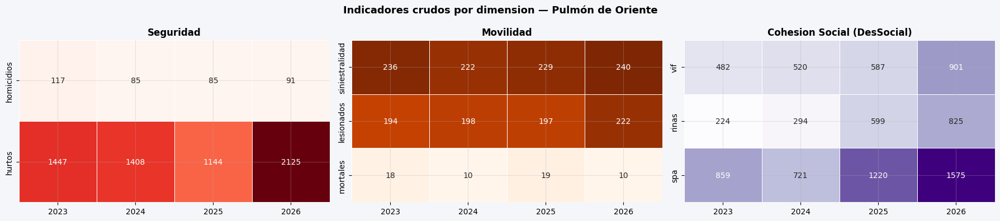

In [85]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4), facecolor=BG)

heat_specs = [
    (axes[0], ["homicidios","hurtos"], "Seguridad", "Reds"),
    (axes[1], ["siniestralidad","lesionados","mortales"], "Movilidad", "Oranges"),
    (axes[2], ["vif","rinas","spa"], "Cohesion Social (DesSocial)", "Purples"),
]
for ax, cols_h, titulo, cmap in heat_specs:
    data = base.set_index("año")[cols_h].T
    sns.heatmap(data, annot=True, fmt=".0f", cmap=cmap, ax=ax, cbar=False,
                linewidths=0.5, linecolor="white")
    ax.set_title(titulo, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("")

fig.suptitle(f"Indicadores crudos por dimension — {ZONA_NOMBRE}", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("pulmon_oriente_heatmap_indicadores.png", dpi=150, bbox_inches="tight", facecolor=BG)
plt.show()


## Celda 16B — Heatmaps trimestrales por indicador (Seguridad, Movilidad, DesSocial)

Año × trimestre, un panel por indicador, usando `corr_trim` (ya construido en la Celda 6, con `NaN`
donde la fuente aún no tiene cobertura — ver nota de 2026 parcial). Mismo patrón que las Celdas 9/10/11
de `04_itt_barrio_obrero_5dim.ipynb`: conteos crudos, no scores normalizados (la normalización solo aplica
al nivel anual para el cálculo del ITT, igual que en Obrero).

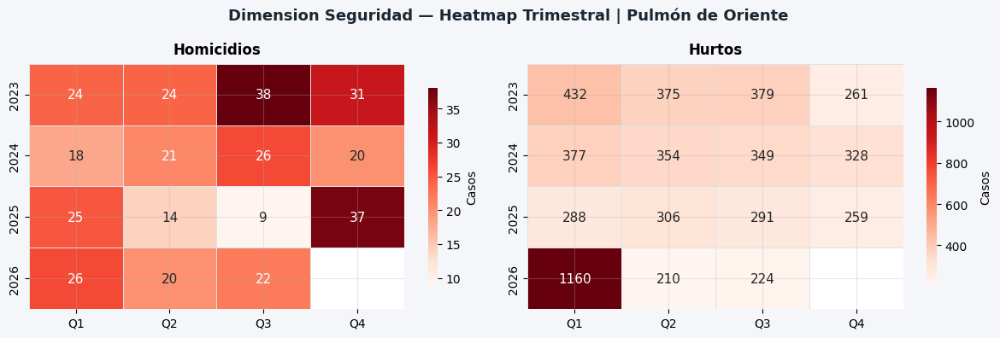

In [86]:
def heatmap_trimestral(cols_h, titulo_dim, cmap):
    n = len(cols_h)
    fig, axes = plt.subplots(1, n, figsize=(6 * n, 4), facecolor=BG)
    if n == 1:
        axes = [axes]
    fig.suptitle(f"Dimension {titulo_dim} — Heatmap Trimestral | {ZONA_NOMBRE}",
                 fontsize=13, fontweight="bold", color="#1B2631")
    for ax, (col, etiqueta) in zip(axes, cols_h):
        pivot = corr_trim.pivot(index="año", columns="trimestre", values=col)
        pivot.columns = ["Q1", "Q2", "Q3", "Q4"]
        mask_nan = pivot.isna()
        sns.heatmap(pivot, annot=True, fmt=".0f", cmap=cmap, mask=mask_nan,
                    linewidths=0.5, linecolor="#DEE2E6", ax=ax,
                    annot_kws={"size": 11}, cbar_kws={"label": "Casos", "shrink": 0.8})
        ax.set_title(etiqueta, fontweight="bold", pad=8)
        ax.set_xlabel("")
        ax.set_ylabel("")
    plt.tight_layout()
    return fig

fig_seg = heatmap_trimestral([("homicidios","Homicidios"), ("hurtos","Hurtos")], "Seguridad", "Reds")
fig_seg.savefig("pulmon_oriente_heatmap_trim_seguridad.png", dpi=150, bbox_inches="tight", facecolor=BG)
plt.show()


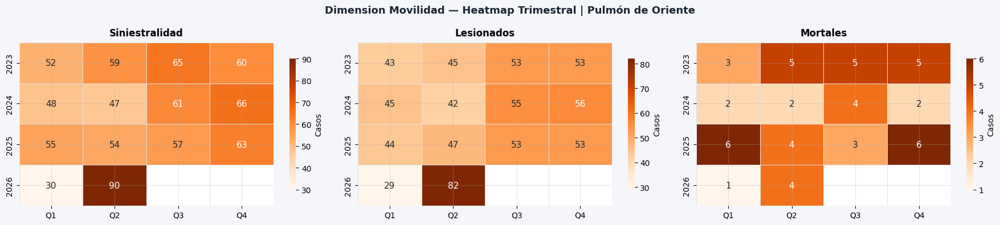

In [87]:
fig_mov = heatmap_trimestral(
    [("siniestralidad","Siniestralidad"), ("lesionados","Lesionados"), ("mortales","Mortales")],
    "Movilidad", "Oranges")
fig_mov.savefig("pulmon_oriente_heatmap_trim_movilidad.png", dpi=150, bbox_inches="tight", facecolor=BG)
plt.show()


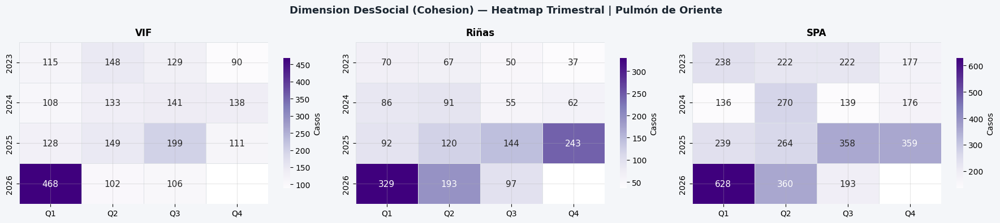

In [88]:
fig_ds = heatmap_trimestral(
    [("vif","VIF"), ("rinas","Riñas"), ("spa","SPA")],
    "DesSocial (Cohesion)", "Purples")
fig_ds.savefig("pulmon_oriente_heatmap_trim_dessocial.png", dpi=150, bbox_inches="tight", facecolor=BG)
plt.show()


## Celda 16C — Evolución trimestral por indicador (línea + área)

Función reutilizable idéntica a la Celda 12/13/14 de Obrero: relleno bajo la línea, hueco visible donde
el valor es `NaN` (sin dato), y una línea vertical punteada marcando el último período con dato real —
para que no se confunda "sin dato todavía" con "cero".

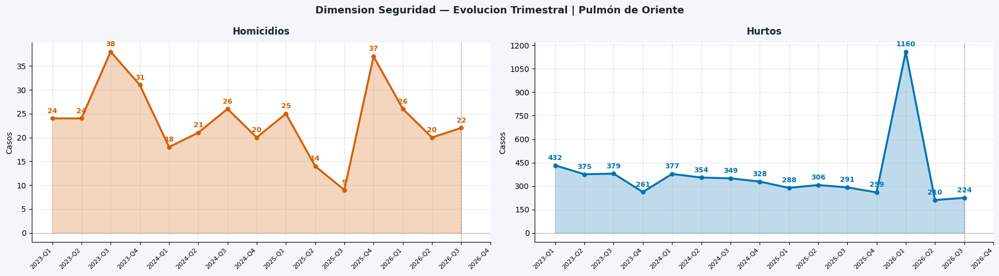

In [89]:
periodos = corr_trim["periodo"].values
x = list(range(len(periodos)))

def plot_linefill(ax, col, titulo, color):
    vals = corr_trim[col].values.astype(float)
    valid = ~pd.isna(vals)
    ax.fill_between(x, np.where(valid, vals, np.nan), alpha=0.25, color=color)
    ax.plot(x, np.where(valid, vals, np.nan), color=color,
            linewidth=2.5, marker="o", markersize=5, zorder=3)
    for i, v in enumerate(vals):
        if pd.notna(v) and v > 0:
            ax.annotate(str(int(v)), (i, v), textcoords="offset points", xytext=(0, 7),
                        ha="center", fontsize=9, fontweight="bold", color=color)
    ultimo_valido = max(i for i, v in enumerate(vals) if pd.notna(v))
    ax.axvline(ultimo_valido, color=OKI_GRIS, linewidth=0.8, linestyle="--", alpha=0.4)
    ax.set_xticks(x)
    ax.set_xticklabels(periodos, rotation=45, ha="right", fontsize=8)
    ax.set_title(titulo, fontweight="bold", pad=10, color="#1B2631")
    ax.set_ylabel("Casos")
    ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.axhline(0, color=OKI_GRIS, linewidth=0.5, alpha=0.4)

fig, axes = plt.subplots(1, 2, figsize=(18, 5), facecolor=BG)
fig.suptitle(f"Dimension Seguridad — Evolucion Trimestral | {ZONA_NOMBRE}",
             fontsize=13, fontweight="bold", color="#1B2631")
plot_linefill(axes[0], "homicidios", "Homicidios", OKI_BERMELL)
plot_linefill(axes[1], "hurtos", "Hurtos", OKI_AZUL)
plt.tight_layout()
plt.savefig("pulmon_oriente_evol_trim_seguridad.png", dpi=150, bbox_inches="tight", facecolor=BG)
plt.show()


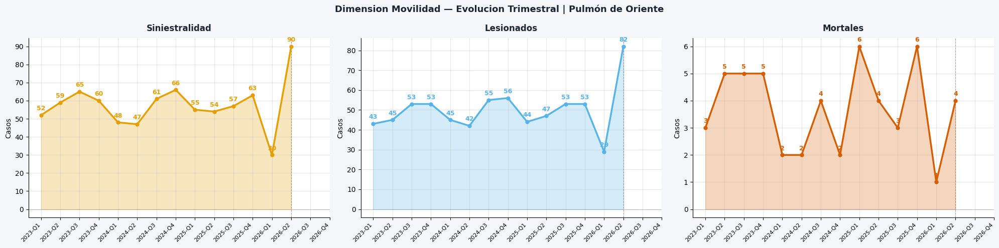

In [90]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5), facecolor=BG)
fig.suptitle(f"Dimension Movilidad — Evolucion Trimestral | {ZONA_NOMBRE}",
             fontsize=13, fontweight="bold", color="#1B2631")
plot_linefill(axes[0], "siniestralidad", "Siniestralidad", OKI_NARANJA)
plot_linefill(axes[1], "lesionados", "Lesionados", OKI_AZUL_C)
plot_linefill(axes[2], "mortales", "Mortales", OKI_BERMELL)
plt.tight_layout()
plt.savefig("pulmon_oriente_evol_trim_movilidad.png", dpi=150, bbox_inches="tight", facecolor=BG)
plt.show()


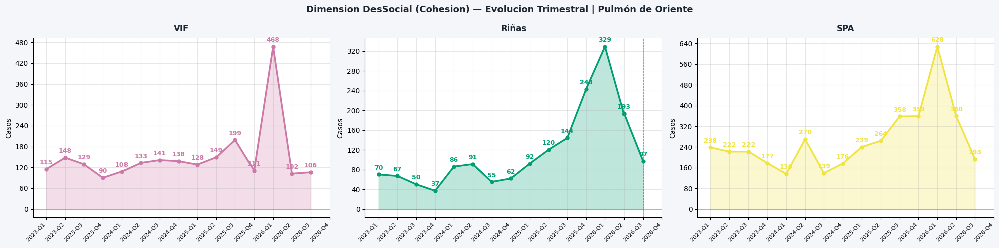

In [91]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5), facecolor=BG)
fig.suptitle(f"Dimension DesSocial (Cohesion) — Evolucion Trimestral | {ZONA_NOMBRE}",
             fontsize=13, fontweight="bold", color="#1B2631")
plot_linefill(axes[0], "vif", "VIF", OKI_MORADO)
plot_linefill(axes[1], "rinas", "Riñas", OKI_VERDE)
plot_linefill(axes[2], "spa", "SPA", OKI_AMARILLO)
plt.tight_layout()
plt.savefig("pulmon_oriente_evol_trim_dessocial.png", dpi=150, bbox_inches="tight", facecolor=BG)
plt.show()


## Celda 17 — Radar ITT: 5 dimensiones

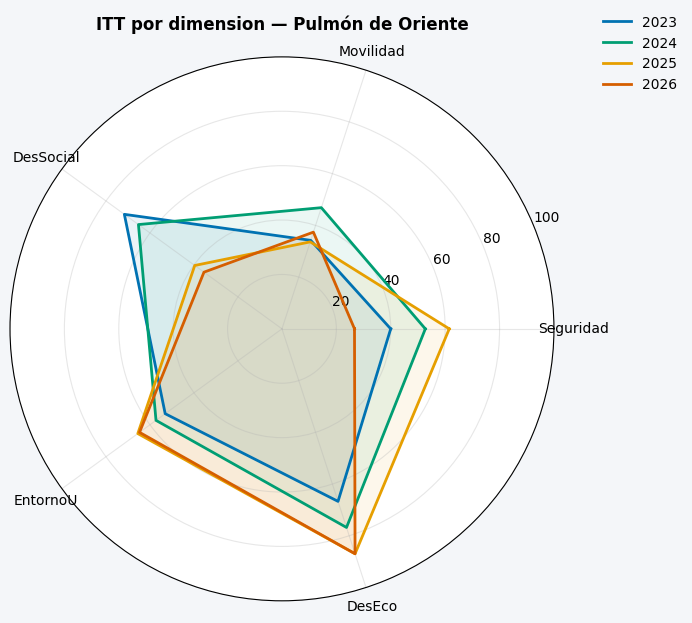

In [92]:
dims_radar  = ["score_seguridad","score_movilidad","score_des_social","score_entorno_u","score_des_eco"]
lbls_radar  = ["Seguridad","Movilidad","DesSocial","EntornoU","DesEco"]
angles = np.linspace(0, 2*np.pi, len(dims_radar), endpoint=False).tolist()
angles += angles[:1]

fig, ax = plt.subplots(figsize=(7, 7), subplot_kw=dict(polar=True), facecolor=BG)
colores_anio = [OKI_AZUL, OKI_VERDE, OKI_NARANJA, OKI_BERMELL]
for i, (_, row) in enumerate(base.iterrows()):
    vals = [row[d] if pd.notna(row[d]) else 0 for d in dims_radar]
    vals += vals[:1]
    ax.plot(angles, vals, linewidth=2, label=str(int(row["año"])), color=colores_anio[i % 4])
    ax.fill(angles, vals, alpha=0.08, color=colores_anio[i % 4])

ax.set_xticks(angles[:-1])
ax.set_xticklabels(lbls_radar)
ax.set_ylim(0, 100)
ax.set_title(f"ITT por dimension — {ZONA_NOMBRE}", fontweight="bold", pad=20)
ax.legend(loc="upper right", bbox_to_anchor=(1.25, 1.1), frameon=False)
plt.tight_layout()
plt.savefig("pulmon_oriente_radar_itt.png", dpi=150, bbox_inches="tight", facecolor=BG)
plt.show()


## Celda 18 — Evolución del ITT y composición por dimensión

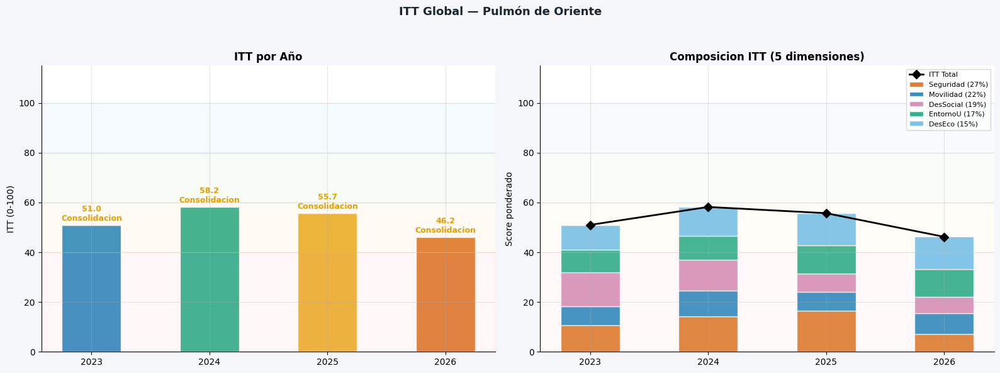

In [93]:
band_configs = [(0,40,"#FFCDD2","Activacion"),(40,60,"#FFE0B2","Consolidacion"),
                (60,80,"#C8E6C9","Transformacion"),(80,100,"#BBDEFB","Escala")]

fig, axes = plt.subplots(1, 2, figsize=(16, 6), facecolor=BG)
fig.suptitle(f"ITT Global — {ZONA_NOMBRE}", fontsize=13, fontweight="bold", color="#1B2631")

ax1 = axes[0]
bars = ax1.bar(base["año"], base["ITT"], color=[OKI_AZUL, OKI_VERDE, OKI_NARANJA, OKI_BERMELL],
                alpha=0.85, edgecolor="white", width=0.5)
for bar, val, nivel, año in zip(bars, base["ITT"], base["nivel"], base["año"]):
    etiqueta = f"{val:.1f}\n{nivel}"
    ax1.text(bar.get_x()+bar.get_width()/2, val+1, etiqueta,
              ha="center", va="bottom", fontsize=9, fontweight="bold",
              color=NIVEL_COLORS.get(nivel, OKI_GRIS))
for y0, y1, c, _ in band_configs:
    ax1.axhspan(y0, y1, alpha=0.15, color=c)
ax1.set_title("ITT por Año", fontweight="bold")
ax1.set_ylim(0, 115)
ax1.set_ylabel("ITT (0-100)")
ax1.set_xticks(base["año"])

ax2 = axes[1]
dims  = ["score_seguridad","score_movilidad","score_des_social","score_entorno_u","score_des_eco"]
lbls  = ["Seguridad","Movilidad","DesSocial","EntornoU","DesEco"]
pesos = [PESOS["Seguridad"], PESOS["Movilidad"], PESOS["DesSocial"], PESOS["EntornoU"], PESOS["DesEco"]]
cols_c = [OKI_BERMELL, OKI_AZUL, OKI_MORADO, OKI_VERDE, OKI_AZUL_C]

bottom = np.zeros(len(base))
for dim, lbl, peso, col in zip(dims, lbls, pesos, cols_c):
    vals = base[dim].fillna(0).values * peso
    ax2.bar(base["año"], vals, bottom=bottom, label=f"{lbl} ({peso:.0%})",
            color=col, alpha=0.8, edgecolor="white", width=0.5)
    bottom += vals
ax2.plot(base["año"], base["ITT"], "D-", color="black", linewidth=2, markersize=7, label="ITT Total", zorder=5)
for y0, y1, c, _ in band_configs:
    ax2.axhspan(y0, y1, alpha=0.1, color=c)
ax2.set_title("Composicion ITT (5 dimensiones)", fontweight="bold")
ax2.set_ylim(0, 115)
ax2.set_ylabel("Score ponderado")
ax2.set_xticks(base["año"])
ax2.legend(loc="upper right", fontsize=8)

plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.savefig("pulmon_oriente_itt_global.png", dpi=150, bbox_inches="tight", facecolor=BG)
plt.show()


## Celda 20 — Exportar a Excel


In [94]:
import openpyxl
from openpyxl.styles import PatternFill, Font, Alignment, Border, Side
from openpyxl.utils import get_column_letter
OUT_DIR = REPO / "outputs" / "itt_pulmon_oriente"
OUT_DIR.mkdir(parents=True, exist_ok=True)
EXPORT_PATH = OUT_DIR / "ITT_Pulmon_Oriente_Consolidado.xlsx"

cols_anual = ["año","score_seguridad","score_movilidad","score_des_social",
              "score_entorno_u","score_des_eco","ITT","nivel"]
df_itt_anual = base[cols_anual].copy().round(2)
df_itt_anual["cobertura"] = df_itt_anual["año"].apply(
    lambda a: "2026 datos a la fecha (DATIC hasta Q1) — guía" if a in ANIOS_PARCIALES else "Año completo")

df_seg = base[["año","homicidios","hurtos","score_homicidios","score_hurtos","score_seguridad"]].round(2)
df_coh = base[["año","vif","rinas","spa","score_vif","score_rinas","score_spa","score_des_social"]].round(2)
df_coh = df_coh.rename(columns={"score_des_social": "score_cohesion_DesSocial"})
df_mov = base[["año","siniestralidad","lesionados","mortales",
               "score_siniestralidad","score_lesionados","score_mortales","score_movilidad"]].round(2)

# Dimensiones aún sin datos para esta zona (fase 1): se documentan como pendientes.
df_pendientes = pd.DataFrame({
    "dimension": ["Polígono oficial"],
    "estado": ["PENDIENTE"],
    "nota": [
        "Polígono aproximado (envolvente de eventos ~568 ha); falta el oficial de planeación.",
    ],
})
# Dimensiones integradas: Entorno Urbano, Desarrollo Económico, Educación
df_eu = base[["año","ndvi","arbolado","score_ndvi","score_arbolado","score_habitabilidad","score_entorno_u"]].round(4).copy()
df_eu["nota"] = "NDVI anual (satelital) + censo arbóreo real (árboles vivos/nuevos dentro del polígono) + habitabilidad (1 - déficit habitacional 2024)."
df_de_export = df_de_scores.round(2) if "df_de_scores" in dir() else pd.DataFrame()
df_edu_export = (df_educ[["año","matricula","desertores","repitentes","tasa_desercion",
                          "tasa_repitencia","score_matricula","score_desercion","score_educ_des"]].round(2)
                 if "df_educ" in dir() else pd.DataFrame())
df_trim_export = corr_trim.copy()
df_meta = pd.DataFrame({
    "campo": ["Zona", "Comunas", "Área aproximada (ha)", "Periodo", "Fuentes con datos",
              "Nota polígono", "Nota VIF"],
    "valor": [ZONA_NOMBRE, COMUNA_PROXY, round(AREA_ZONA_HA, 1), f"{ANIOS[0]}-{ANIOS[-1]} (2026 parcial)",
              "Seguridad, Movilidad, Cohesión, Educación, Desarrollo Económico, Entorno Urbano (NDVI+vivienda)",
              "Aproximado (envolvente de los eventos); polígono oficial pendiente.",
              "Filtrado por los 33 barrios de la zona (no recortado espacialmente)."],
})

sheets = {
    "ITT_Resumen":              df_itt_anual,
    "Seguridad":                df_seg,
    "Movilidad":                df_mov,
    "Cohesion_Social":          df_coh,
    "Educacion":                df_edu_export,
    "Entorno_Urbano":           df_eu,
    "Desarrollo_Economico":     df_de_export,
    "Indicadores_Trimestrales": df_trim_export,
    "Dimensiones_Pendientes":   df_pendientes,
    "Metadatos":                df_meta,
}
with pd.ExcelWriter(str(EXPORT_PATH), engine="openpyxl") as writer:
    for sheet_name, df in sheets.items():
        df.to_excel(writer, sheet_name=sheet_name, index=False)
    wb = writer.book
    header_fill = PatternFill("solid", fgColor="1B4F8A")
    header_font = Font(color="FFFFFF", bold=True)
    for ws in wb.worksheets:
        for cell in ws[1]:
            cell.fill = header_fill
            cell.font = header_font
            cell.alignment = Alignment(horizontal="center", wrap_text=True)
        for col in ws.columns:
            max_len = max((len(str(c.value)) for c in col if c.value), default=8)
            ws.column_dimensions[get_column_letter(col[0].column)].width = min(max_len + 2, 40)
print(f"Exportado: {EXPORT_PATH}  ({len(sheets)} hojas)")
print("5 dimensiones integradas (incluye censo arbóreo real). Pendiente: polígono oficial de planeación.")


Exportado: /content/itt_repos_cali/outputs/itt_pulmon_oriente/ITT_Pulmon_Oriente_Consolidado.xlsx  (10 hojas)
5 dimensiones integradas (incluye censo arbóreo real). Pendiente: polígono oficial de planeación.
